In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [2]:
# define state
class BMIState(TypedDict):
    weight_kg: float
    height_m: float
    category: str
    bmi: float

In [3]:
def cal_bmi(state : BMIState) -> BMIState:
    weight = state['weight_kg']
    height = state['height_m']
    bmi = weight / (height ** 2)
    state['bmi'] = round(bmi, 2)

    return state

In [4]:
def set_category(state : BMIState) -> BMIState:
    bmi = state['bmi']

    if bmi < 18.5:
        state['category'] = "Underweight"
    elif bmi < 25:
        state['category'] = "Normal"
    elif bmi < 25:
        state['category'] = "Overweight"
    else:
        state['category'] = "Obese"
    
    return state

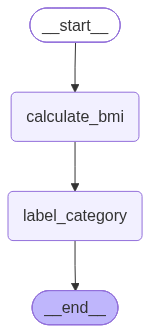

In [6]:
# define graph

graph = StateGraph(BMIState)

graph.add_node("calculate_bmi", cal_bmi)
graph.add_node("label_category", set_category)

graph.add_edge(START, "calculate_bmi")
graph.add_edge("calculate_bmi", "label_category")
graph.add_edge("label_category", END)

workflow = graph.compile()
workflow

In [7]:
initial_state = {'weight_kg' : 75, 'height_m' : 1.77}


final_state = workflow.invoke(initial_state)
final_state

{'weight_kg': 75, 'height_m': 1.77, 'category': 'Normal', 'bmi': 23.94}

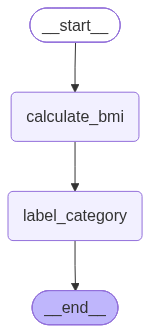

In [8]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())